# Bài 01: Python và NumPy cho Xử lý Ảnh — Từ Danh sách Số đến Tensor Đa chiều

## 1. Mục tiêu học tập
- Ôn tập nhanh các cấu trúc Python thiết yếu trong pipeline AI: `list`, `dict`, `tuple`, hàm (`def`) và lớp (`class`).
- Hiểu sâu cấu trúc mảng `numpy.ndarray`: `ndim` (số chiều), `shape` (kích thước từng chiều), `dtype` (kiểu dữ liệu số), `axis` (trục tính toán).
- Thành thạo 3 kỹ thuật cốt lõi giúp xử lý ảnh nhanh gấp hàng chục lần vòng lặp thuần Python:
  1. `Slicing` & `Boolean Indexing` (Cắt vùng ảnh `ROI` và lọc pixel theo ngưỡng).
  2. `Broadcasting` (Tự động mở rộng chiều khi cộng/nhân hai mảng khác kích thước).
  3. `Vectorization` (Vector hóa phép toán trên toàn bộ mảng ảnh).

## 2. Kiến thức cần có
- Đã hoàn thành `00_start_here.ipynb`.

## 3. Thời gian học dự kiến
- Khoảng **90 – 120 phút** (ước tính).

## 4. Bài toán thực tế đơn giản
Khi cần tăng độ sáng cho kênh màu Đỏ (`Red`) thêm `30` đơn vị, cắt lấy vùng trung tâm bức ảnh (`crop`) và xóa nền tối về màu đen: nếu dùng 3 vòng lặp `for` lồng nhau `(y, x, c)` trong Python thuần trên ảnh Full HD (`1080 x 1920 x 3` = `6.2 triệu` phép tính), chương trình sẽ rất chậm. Với `NumPy`, toàn bộ thao tác chỉ mất vài mili-giây.

## 5. Giải thích trực quan: Scalar → Vector → Matrix → 3D/4D Tensor
- **Scalar (Vô hướng, `0D`)**: Một con số đơn lẻ, ví dụ độ sáng của 1 điểm ảnh `128`, `shape = ()`.
- **Vector (Vector, `1D`)**: Một dãy số, ví dụ bộ màu RGB của 1 pixel `[220, 80, 60]`, `shape = (3,)`.
- **Matrix (Ma trận, `2D`)**: Một bảng số hàng × cột, ví dụ 1 bức ảnh xám cao `H`, rộng `W`, `shape = (H, W)`.
- **3D Array / Tensor (`3D`)**: Một bức ảnh màu gồm 3 mặt phẳng kênh ghép lại, `shape = (H, W, 3)`.
- **4D Batch Tensor (`4D`)**: Một lô gồm $N$ bức ảnh màu, `shape = (N, H, W, 3)` (trong NumPy) hoặc `(N, 3, H, W)` (trong PyTorch).

## 6. Thuật ngữ mới & Giải thích Keyword
| Keyword | Nghĩa tiếng Việt | Nhóm | Kiểu / Đơn vị | Vai trò & Ảnh hưởng khi thay đổi |
|---|---|---|---|---|
| `ndarray` | Mảng N-chiều đồng nhất kiểu | Dữ liệu | `np.ndarray` | Lưu trữ các phần tử liên tiếp nhau trong bộ nhớ C, cho phép tính toán song song SIMD. |
| `shape` | Kích thước các chiều | Dữ liệu | `tuple[int, ...]` | Ví dụ `(32, 48, 3)` tương ứng `(Height=32, Width=48, Channels=3)`. Lưu ý: `shape[0]` là chiều cao `H` (số hàng `y`), `shape[1]` là chiều rộng `W` (số cột `x`). |
| `dtype` | Kiểu dữ liệu phần tử | Dữ liệu | `np.uint8`, `np.float32`, `np.int64` | `uint8` chỉ chứa số nguyên không dấu `0..255` (1 byte/pixel). Nếu cộng vượt `255` trên `uint8` sẽ bị tràn số quay vòng (`250 + 20 = 14`!). |
| `axis` | Trục thực hiện phép gộp | Dữ liệu | `int` hoặc `tuple[int]` | Xác định chiều nào sẽ bị **thu gọn (collapsed)** khi gọi `.sum()`, `.mean()`, `.max()`. Ví dụ trên ảnh `(H, W, C)`, `img.mean(axis=(0, 1))` gộp hết chiều `H` và `W`, giữ lại vector trung bình `(C,)` của 3 kênh màu. |
| `broadcasting` | Cơ chế tự khớp chiều | Dữ liệu | Quy tắc NumPy | Cho phép thực hiện phép toán giữa ảnh `(H, W, 3)` và vector màu `(1, 1, 3)` hoặc `(3,)` mà không cần nhân bản bộ nhớ. |
| `vectorization` | Vector hóa phép toán | Tối ưu hóa | Kỹ thuật lập trình | Thay vòng lặp `for` Python bằng phép toán cấp mảng của NumPy/PyTorch. |

## 7. Công thức & Quy tắc Broadcasting, Ví dụ số nhỏ
- **Quy tắc Broadcasting của NumPy**: Khi thực hiện phép toán giữa hai mảng `A` và `B`, NumPy so sánh kích thước các chiều **từ phải sang trái**. Hai chiều tương ứng là hợp lệ nếu:
  1. Chúng **bằng nhau**, HOẶC
  2. Một trong hai chiều **bằng `1`** (hoặc tự động chèn `1` vào bên trái mảng ít chiều hơn).
- **Ví dụ số nhỏ**:
  - Ảnh `A` có `shape = (32, 32, 3)`.
  - Vector hệ số cân bằng trắng `w` có `shape = (3,)` → được hiểu là `(1, 1, 3)` → tương thích hoàn hảo với `(32, 32, 3)`!
  - Nhưng nếu vector `v` có `shape = (32,)` → so từ phải sang trái: `3 != 32` → Báo lỗi `ValueError: operands could not be broadcast together`!


In [1]:
# Cell 1: Khởi tạo môi trường và ôn tập cấu trúc dữ liệu Python cho quản lý cấu hình AI
import sys
import time
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from src.utils import set_seed

set_seed(42)

# Cấu trúc class và dict chuẩn để quản lý thông tin một mẫu ảnh
class ImageSampleRecord:
    def __init__(self, sample_id: int, image: np.ndarray, label_name: str) -> None:
        self.sample_id = sample_id
        self.image = image
        self.label_name = label_name

    def summary(self) -> dict:
        return {
            "id": self.sample_id,
            "label": self.label_name,
            "shape": self.image.shape,
            "dtype": str(self.image.dtype),
            "mean": round(float(self.image.mean()), 2),
        }

toy_img = np.zeros((16, 24, 3), dtype=np.uint8)
toy_img[4:12, 6:18] = [220, 90, 50]  # Slicing: gán màu cam cho vùng chữ nhật giữa ảnh
rec = ImageSampleRecord(sample_id=1, image=toy_img, label_name="rectangle_roi")
print("Thông tin mẫu ảnh:", rec.summary())


Thông tin mẫu ảnh: {'id': 1, 'label': 'rectangle_roi', 'shape': (16, 24, 3), 'dtype': 'uint8', 'mean': 30.0}


In [2]:
# Cell 2: Kiểm tra sâu về shape, axis và bẫy tràn số (Overflow) của kiểu uint8
# Bẫy kinh điển: Cộng trực tiếp số vào mảng uint8
pixel_u8 = np.array([240, 250], dtype=np.uint8)
overflow_result = pixel_u8 + np.uint8(30)  # 240+30=270 -> 270 % 256 = 14!
safe_result = np.clip(pixel_u8.astype(np.int32) + 30, 0, 255).astype(np.uint8)

print(f"Giá trị gốc (uint8)         : {pixel_u8}")
print(f"Cộng trực tiếp bị tràn số   : {overflow_result}  <-- SAI (270 quay vòng về 14)")
print(f"Cộng an toàn với np.clip    : {safe_result} <-- ĐÚNG (giới hạn ở 255)")

# Minh họa ý nghĩa của tham số axis trên ảnh màu (H=16, W=24, C=3)
mean_per_channel = toy_img.mean(axis=(0, 1))  # Gộp chiều H(0) và W(1), còn lại chiều C(2)
mean_grayscale = toy_img.mean(axis=2)         # Gộp chiều C(2), còn lại ma trận 2D (H, W)
print(f"Mean theo từng kênh R,G,B (shape {mean_per_channel.shape}): {mean_per_channel.round(2)}")
print(f"Ảnh trung bình kênh (shape {mean_grayscale.shape})")


Giá trị gốc (uint8)         : [240 250]
Cộng trực tiếp bị tràn số   : [14 24]  <-- SAI (270 quay vòng về 14)
Cộng an toàn với np.clip    : [255 255] <-- ĐÚNG (giới hạn ở 255)
Mean theo từng kênh R,G,B (shape (3,)): [55.  22.5 12.5]
Ảnh trung bình kênh (shape (16, 24))


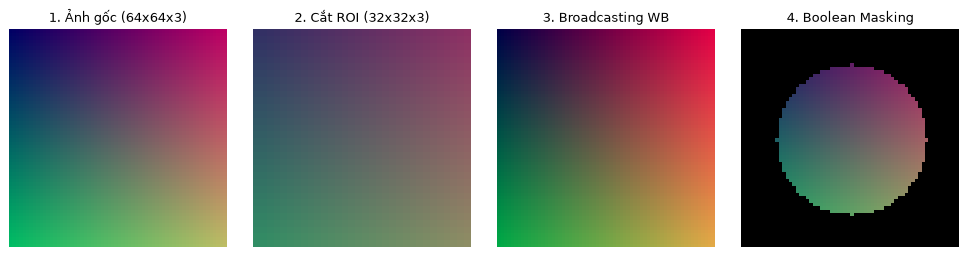

In [3]:
# Cell 3: Thực hành Slicing, Cropping, Boolean Masking và Broadcasting
# Tạo ảnh gradient tổng hợp kích thước (64, 64, 3)
y_idx, x_idx = np.mgrid[0:64, 0:64]
img_grad = np.stack([x_idx * 3, y_idx * 3, np.full_like(x_idx, 100)], axis=-1).astype(np.uint8)

# 1. Cắt vùng quan tâm (ROI Cropping): lấy từ hàng 16..48, cột 16..48
roi_crop = img_grad[16:48, 16:48].copy()

# 2. Broadcasting: nhân hệ số cân bằng trắng [1.2, 0.9, 0.7] có shape (3,) vào ảnh (64, 64, 3)
wb_gains = np.array([1.2, 0.9, 0.7], dtype=np.float32)
img_wb = np.clip(img_grad.astype(np.float32) * wb_gains, 0, 255).astype(np.uint8)

# 3. Boolean Masking: tạo mặt nạ hình tròn ở tâm và đặt nền ngoài hình tròn về màu đen
dist_sq = (x_idx - 32) ** 2 + (y_idx - 32) ** 2
circle_mask = dist_sq <= (22 ** 2)  # Mảng bool (64, 64)
img_masked = img_grad.copy()
img_masked[~circle_mask] = 0

fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
for ax, im, title in zip(
    axes,
    [img_grad, roi_crop, img_wb, img_masked],
    ["1. Ảnh gốc (64x64x3)", "2. Cắt ROI (32x32x3)", "3. Broadcasting WB", "4. Boolean Masking"],
):
    ax.imshow(im)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()


In [4]:
# Cell 4: Thí nghiệm thay đổi một yếu tố — So sánh tốc độ Vòng lặp Python vs Vectorization
test_img = np.random.randint(0, 256, size=(128, 128, 3), dtype=np.uint8)

# Cách 1: Dùng vòng lặp for thuần Python để đảo ngược màu (255 - pixel)
t0 = time.perf_counter()
out_loop = np.empty_like(test_img)
h, w, c = test_img.shape
for y in range(h):
    for x in range(w):
        for ch in range(c):
            out_loop[y, x, ch] = 255 - test_img[y, x, ch]
loop_ms = (time.perf_counter() - t0) * 1000.0

# Cách 2: Dùng Vectorization của NumPy
t1 = time.perf_counter()
out_vec = 255 - test_img
vec_ms = (time.perf_counter() - t1) * 1000.0

assert np.array_equal(out_loop, out_vec), "Kết quả hai cách phải giống hệt nhau!"
speedup = loop_ms / max(vec_ms, 1e-4)
print(f"Thời gian chạy vòng lặp Python : {loop_ms:.3f} ms")
print(f"Thời gian chạy Vectorization   : {vec_ms:.4f} ms")
print(f"--> Vectorization nhanh gấp    : ~{speedup:.1f} lần!")


Thời gian chạy vòng lặp Python : 12.329 ms
Thời gian chạy Vectorization   : 0.0284 ms
--> Vectorization nhanh gấp    : ~434.1 lần!


## 11. Nhận xét cách đọc kết quả
- Phép cắt lát `img[y1:y2, x1:x2]` trong NumPy mặc định trả về một **view** (tham chiếu chung vùng nhớ với ảnh gốc). Vì vậy ở Cell 3 ta gọi `.copy()` khi muốn chỉnh sửa `roi_crop` độc lập mà không làm hỏng `img_grad`.
- Ở Cell 4, `Vectorization` (`255 - test_img`) cho kết quả giống hệt 3 vòng lặp `for` nhưng nhanh hơn hàng trăm lần nhờ thực thi ở tầng C đã biên dịch sẵn.

## 13. Lỗi thường gặp và cách sửa
1. **Nhầm thứ tự tọa độ `(x, y)` với chỉ số mảng `(row, col) = (y, x)`**: Trong NumPy, chỉ số đầu tiên luôn là **hàng (`y` - chiều dọc)**, chỉ số thứ hai mới là **cột (`x` - chiều ngang)**: `img[y, x]`.
2. **Sửa nhầm ảnh gốc do quên `.copy()` trên slice**: Luôn dùng `sub_img = img[y1:y2, x1:x2].copy()` nếu bạn định gán giá trị mới lên `sub_img`.
3. **Tràn số `uint8` khi cộng/trừ độ sáng**: Luôn ép sang `float32` hoặc `int32`, tính toán, rồi dùng `np.clip(..., 0, 255).astype(np.uint8)`.

## 14. Bài tập tự làm
- **Cơ bản**: Tạo một ảnh bàn cờ vua (`checkerboard`) kích thước `(64, 64)` kiểu `uint8` gồm các ô vuông `8x8` xen kẽ màu đen (`0`) và trắng (`255`) bằng slicing hoặc phép chia lấy nguyên `//`.
- **Trung cấp**: Cho một lô gồm `10` ảnh màu `(10, 32, 32, 3)` kiểu `float32`. Dùng `broadcasting` để chuẩn hóa từng kênh màu theo công thức `(X - mean) / std` trong đó `mean` và `std` có shape `(3,)`.
- **Nâng cao**: Không dùng vòng lặp `for`, hãy tính khoảng cách Euclidean từ một vector truy vấn `q` có shape `(128,)` tới toàn bộ `500` vector cơ sở dữ liệu `DB` có shape `(500, 128)`.

## 15. Gợi ý và Lời giải
- *Gợi ý*: Với bàn cờ, dùng `(y // 8 + x // 8) % 2`. Với khoảng cách Euclidean, dùng `np.linalg.norm(DB - q, axis=1)`.


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 01
# 1. Cơ bản: Tạo ảnh bàn cờ vua 64x64 với ô 8x8
yy, xx = np.mgrid[0:64, 0:64]
checkerboard = (((yy // 8) + (xx // 8)) % 2 * 255).astype(np.uint8)
print("[Cơ bản] Checkerboard shape:", checkerboard.shape, "unique values:", np.unique(checkerboard))

# 2. Trung cấp: Chuẩn hóa lô 10 ảnh bằng broadcasting
batch_imgs = np.random.rand(10, 32, 32, 3).astype(np.float32)
ch_mean = batch_imgs.mean(axis=(0, 1, 2))          # shape (3,)
ch_std = batch_imgs.std(axis=(0, 1, 2)) + 1e-6     # shape (3,)
batch_norm = (batch_imgs - ch_mean) / ch_std
print("[Trung cấp] Mean sau chuẩn hóa:", batch_norm.mean(axis=(0, 1, 2)).round(4))

# 3. Nâng cao: Tính khoảng cách Euclidean vector hóa
db_vectors = np.random.randn(500, 128).astype(np.float32)
query_vec = np.random.randn(128).astype(np.float32)
distances = np.linalg.norm(db_vectors - query_vec, axis=1)
nearest_idx = int(np.argmin(distances))
print(f"[Nâng cao] Distances shape: {distances.shape}, mẫu gần nhất: #{nearest_idx} (dist={distances[nearest_idx]:.3f})")


[Cơ bản] Checkerboard shape: (64, 64) unique values: [  0 255]
[Trung cấp] Mean sau chuẩn hóa: [-0. -0. -0.]
[Nâng cao] Distances shape: (500,), mẫu gần nhất: #13 (dist=13.650)


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã nắm vững `shape`, `dtype`, `axis`, `slicing`, `broadcasting`, `vectorization`.
- [x] Không còn mắc lỗi tràn số `uint8` hoặc nhầm `(y, x)` với `(x, y)`.
- [x] Sẵn sàng chuyển sang **Bài 02: `02_image_fundamentals.ipynb`**.

## 17. Nguồn tham khảo
- NumPy Broadcasting Documentation: https://numpy.org/doc/stable/user/basics.broadcasting.html
- Harris, C. R. et al. (2020), *Array programming with NumPy*, Nature 585, 357–362.
